# Baseline: one XGBoost classifier per unit

Goal: get a first read on how hard this problem is, and where the biggest weaknesses are,
before investing in feature engineering.

**Plan (agreed beforehand):**
- Use the centralized table from `build_modeling_table.py` (`data/processed/train_hourly.parquet`)
  as-is — raw joined features, no engineering.
- **Chronological validation split**: train on 2015–2021, validate on **2022** (held out as a
  whole year). Not a random split — 2022 was the price-crisis outlier we found in the EDA, and a
  random split would let the model see neighbouring hours from the same week, inflating the score.
- **One independent XGBoost binary classifier per unit** (14 models), same raw feature set for all.
- **Metric**: the competition's own `kaggle_metric.py` (micro-average ROC-AUC), applied for real by
  reshaping our validation predictions back into the competition's wide submission format — plus a
  per-unit AUC breakdown that the pooled metric hides.


In [1]:
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../..")
from kaggle_metric import score as kaggle_score

# --- dataviz palette (see project dataviz skill / references/palette.md) ---
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE_COLOR,
    "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "grid.color": GRID,
    "axes.grid": True, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 11, "figure.dpi": 110,
})


## 1. Load the centralized table and split chronologically

In [2]:
train_df = pd.read_parquet("../../data/processed/train_hourly.parquet")
train_df["year"] = train_df["starttime"].dt.year

target_cols = [c for c in train_df.columns if c.startswith("on_")]
units = [c[len("on_"):] for c in target_cols]
feature_cols = [c for c in train_df.columns
                if c not in ("run_no", "split", "starttime", "timestamp", "year") and c not in target_cols]

is_val = train_df["year"] == 2022
fit_df, val_df = train_df[~is_val], train_df[is_val]

print(f"{len(feature_cols)} features:", feature_cols)
print(f"\nfit  cases: {fit_df['run_no'].nunique():4d}  rows: {len(fit_df):,}  (years {fit_df['year'].min()}-{fit_df['year'].max()})")
print(f"val  cases: {val_df['run_no'].nunique():4d}  rows: {len(val_df):,}  (year {val_df['year'].unique()})")


54 features: ['hour', 'price_eur_mwh', 'inflow_Langesae', 'inflow_Staavatn', 'inflow_Kjelavatn', 'inflow_Bordalsvatn', 'inflow_Foersvatn', 'inflow_Hyljelihyl', 'inflow_Venemo', 'inflow_Bitdalsvatn', 'inflow_Songavatn', 'inflow_Totak', 'inflow_Vaamarvatn', 'inflow_Langeidvatn', 'inflow_Vatjern', 'inflow_Vinjevatn', 'inflow_Botnedalsvatn', 'inflow_Byrtevatn', 'inflow_Bandak', 'inflow_r_Vest_Vassdraget', 'storage_Kjelavatn', 'storage_Staavatn', 'storage_Langesae', 'storage_Foersvatn', 'storage_Venemo', 'storage_Botnedalsvatn', 'storage_Bitdalsvatn', 'storage_Vaamarvatn', 'storage_Langeidvatn', 'storage_Totak', 'storage_Songavatn', 'storage_Vinjevatn', 'storage_Bandak', 'storage_Bordalsvatn', 'storage_Byrtevatn', 'storage_Hyljelihyl', 'storage_Vatjern', 'water_value_Kjelavatn', 'water_value_Staavatn', 'water_value_Langesae', 'water_value_Foersvatn', 'water_value_Venemo', 'water_value_Botnedalsvatn', 'water_value_Bitdalsvatn', 'water_value_Vaamarvatn', 'water_value_Langeidvatn', 'water_valu

## 2. Train one XGBoost model per unit

In [3]:
X_fit, X_val = fit_df[feature_cols], val_df[feature_cols]

models = {}
val_pred = pd.DataFrame({"run_no": val_df["run_no"].values, "hour": val_df["hour"].values})

for u in units:
    y_fit = fit_df[f"on_{u}"]
    model = XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=0,
    )
    model.fit(X_fit, y_fit)
    models[u] = model
    val_pred[f"pred_{u}"] = model.predict_proba(X_val)[:, 1]

print("trained", len(models), "models")


trained 14 models


## 3. Score with the competition's own metric

In [4]:
# Reshape long-format predictions back into the competition's wide submission format
wide_frames = []
for u in units:
    piv = val_pred.pivot(index="run_no", columns="hour", values=f"pred_{u}")
    piv.columns = [f"result_committed_{u}_t{h}" for h in piv.columns]
    wide_frames.append(piv)
submission_val = pd.concat(wide_frames, axis=1).reset_index().rename(columns={"run_no": "Run No"})

uc = pd.read_csv("../../data/kernel/Unit_commitment_decisions.csv")
solution_val = uc[uc["Run No"].isin(val_df["run_no"].unique())]

overall_auc = kaggle_score(solution_val, submission_val)
print(f"Overall micro-average ROC-AUC (2022 validation, competition metric): {overall_auc:.4f}")


Overall micro-average ROC-AUC (2022 validation, competition metric): 0.6473


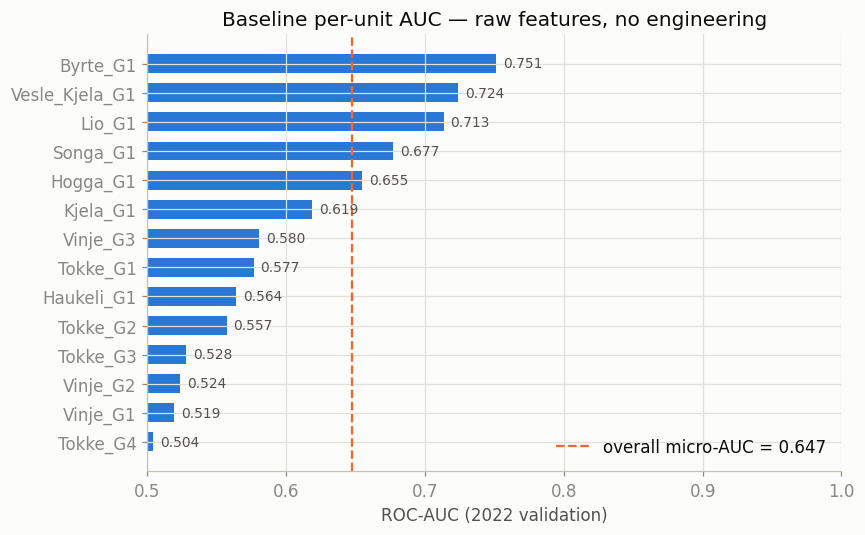

Byrte_G1          0.750969
Vesle_Kjela_G1    0.723788
Lio_G1            0.713363
Songa_G1          0.676782
Hogga_G1          0.654844
Kjela_G1          0.618756
Vinje_G3          0.580332
Tokke_G1          0.576513
Haukeli_G1        0.563680
Tokke_G2          0.556981
Tokke_G3          0.527619
Vinje_G2          0.523580
Vinje_G1          0.519480
Tokke_G4          0.503888
dtype: float64

In [5]:
per_unit_auc = pd.Series({
    u: roc_auc_score(val_df[f"on_{u}"], val_pred[f"pred_{u}"])
    for u in units
}).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(per_unit_auc.index, per_unit_auc.values, color=CAT[0], height=0.65)
ax.axvline(overall_auc, color=CAT[1], lw=1.5, ls="--", label=f"overall micro-AUC = {overall_auc:.3f}")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("ROC-AUC (2022 validation)")
ax.set_title("Baseline per-unit AUC — raw features, no engineering")
ax.legend(frameon=False, loc="lower right")
for y, v in enumerate(per_unit_auc.values):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9, color=INK_SECONDARY)
plt.tight_layout()
plt.show()

per_unit_auc.sort_values(ascending=False)


## 4. What does the model actually lean on?

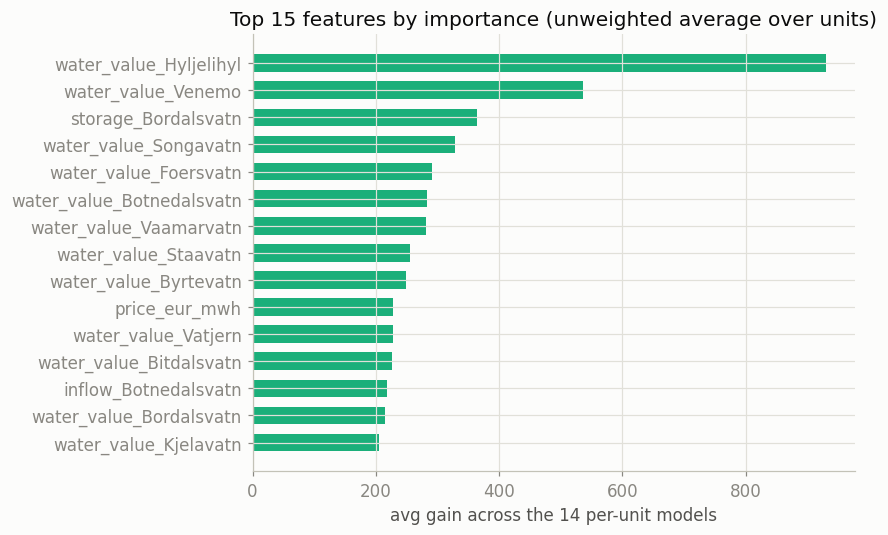

In [6]:
# Aggregate feature importances (gain) across all 14 per-unit models, as a first sanity check
imp = pd.DataFrame({u: pd.Series(m.get_booster().get_score(importance_type="gain"))
                     for u, m in models.items()}).fillna(0)
avg_imp = imp.mean(axis=1).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(avg_imp.index[::-1], avg_imp.values[::-1], color=CAT[2], height=0.65)
ax.set_xlabel("avg gain across the 14 per-unit models")
ax.set_title("Top 15 features by importance (unweighted average over units)")
plt.tight_layout()
plt.show()


## 5. Where this leaves us

This is deliberately the simplest thing that could work: raw joined features, default-ish XGBoost
hyperparameters, no tuning, no engineered features. The numbers above are the baseline to beat, and
the per-unit breakdown + feature importances are what we should look at together to decide what's
worth investing in next (e.g. the within-week price normalization idea from the EDA, per-unit
imbalance handling, or something the importances surface that we haven't discussed yet).
